# Query-Based Object Detection: RT-DETR on VisDrone

**Coursework section:** Query-based (0.75 pt)  
**Model:** RT-DETR (transformer-based detector)  
**Environment:** Kaggle GPU notebook  

## 1. Objective and hypothesis

We investigate a query-based detector and compare it with CNN-based object detectors evaluated on the **same VisDrone validation frames**. The focus is on small objects and crowded aerial scenes.

Our key questions are:
1. Does RT-DETR detect small and densely packed objects as reliably as Faster R-CNN / RetinaNet?
2. How do learning rate and input resolution affect convergence and detection quality under a limited training budget?
3. How does validation mAP evolve during RT-DETR training compared with a CNN baseline?

**Previous CNN reference** (recorded earlier, not measured by this notebook): Faster R-CNN, mAP@50:95 = **0.1675**, AP50 = **0.3611**, AP_small = **0.0873**, **4.1 FPS** at validation `--step 5`. Because model families and preprocessing differ, this is an informative benchmark, not a fully controlled causal comparison.

**Status:** executable experiment plan; performance tables and conclusions must be filled from actual training results. No extra per-epoch full-set evaluations are included.


## 2. Model theory: queries and bipartite matching

RT-DETR is a **query-based object detector**. A CNN backbone extracts image features, while the transformer decoder uses learned object queries to predict a fixed set of candidate objects. Each query predicts a class and a bounding box.

During training, **Hungarian (bipartite) matching** finds a one-to-one assignment between ground-truth objects and queries. Unmatched queries are trained as background/no-object. This discourages duplicate predictions and makes ordinary per-image NMS unnecessary in the model's standard prediction path.

**Dense scenes:** if a frame has more distinguishable objects than the available effective queries, recall may be limited; crowded small objects are also hard to separate in low-resolution features. We will inspect query count when possible and evaluate `AP_small` and crowded-frame failures.

**Important implementation detail:** the repository's `src.models.rtdetr` shares inference code with `src.models.tiled_yolo`. If tiled inference is enabled, its **cross-tile merging uses NMS**, even though RT-DETR does not require ordinary NMS for its native one-image predictions. For architectural comparison we use **`--tile 0`** first, then leave tiling as an optional ablation.

## 3. Reproducibility and environment setup

- Same source dataset: VisDrone competition
- Train subset: every 20th frame **within each clip** (created reproducibly with `src.make_subset`)
- Validation: original labeled split, every 5th frame (`--step 5`), not a frame-level random split
- Random seed: 42
- Input size: 640 baseline; 800 for a high-resolution tuning experiment
- Epochs: 6 per run (limited-budget comparison)
- Batch size: 1 (memory-safe starting setting; adjust only after a GPU check)

**Note:** the previous Faster R-CNN was trained on a step-20 subset of 1,211 frames. The precise ordering of selected frames may differ between preprocessing scripts. Compare protocol and selected IDs before claiming a strictly matched data ablation.

Training is **disabled by default**. Change `RUN_TRAINING` only when you are ready to use GPU time.

In [1]:
from pathlib import Path
import os, sys, subprocess, time, json

REPO = Path('/kaggle/working/drone-multi-object-detection')
REPO_URL = 'https://github.com/lilialania/drone-multi-object-detection.git'
DATA_ROOT = Path('/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026')
WORK = Path('/kaggle/working/query_rtdetr')
RUNS = WORK / 'runs'
SUBSET = WORK / 'subset_step20'
WORK.mkdir(parents=True, exist_ok=True)
RUNS.mkdir(parents=True, exist_ok=True)

if not (REPO / 'src' / 'rtdetr.py').is_file():
    subprocess.run(['git', 'clone', REPO_URL, str(REPO)], check=True)
os.chdir(REPO)
sys.path.insert(0, str(REPO))

assert (DATA_ROOT / 'train' / 'annotations_coco.json').is_file(), 'Missing train annotations'
assert (DATA_ROOT / 'val' / 'annotations_coco.json').is_file(), 'Missing val annotations'
print('Repository:', REPO)
print('RT-DETR module:', (REPO / 'src' / 'rtdetr.py').exists())
print('Data:', DATA_ROOT)

Cloning into '/kaggle/working/drone-multi-object-detection'...


Repository: /kaggle/working/drone-multi-object-detection
RT-DETR module: True
Data: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


In [2]:
import os
from kaggle_secrets import UserSecretsClient
from huggingface_hub import HfApi

os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

api = HfApi(token=os.environ["HF_TOKEN"])
print("Hugging Face authentication ready")

Hugging Face authentication ready


### Install model dependencies

RT-DETR is implemented with **Ultralytics** in the current repository. Install it only if needed. Internet must be enabled the first time pretrained weights are downloaded.

In [3]:
import importlib.util
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics', 'pycocotools'], check=True)
from ultralytics import RTDETR
import ultralytics
print('Ultralytics:', ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.210


## 4. Prepare the training subset (no data leakage)

The repository's `src.make_subset` selects frames **per sequence**; train and validation retain the original sequence-level split. We generate an Ultralytics-compatible layout (`images/train`, `labels/train`, etc.). The resulting copy can be recreated after a Kaggle reset.

**Ignored-region limitation:** the original data includes ignored areas. `make_subset` copies `ignore/` files, but the plain Ultralytics loader does **not automatically mask them**. This notebook therefore does not claim identical ignored-region handling to a tiled/gray-masked pipeline; document this as a preprocessing limitation. For an exact comparison, use the same ignored-region masking policy across models.

In [4]:
RUN_PREP = True
if RUN_PREP and not (SUBSET / 'data.yaml').exists():
    subprocess.run([
        sys.executable, '-m', 'src.make_subset',
        '--data-root', str(DATA_ROOT),
        '--output-dir', str(SUBSET),
        '--step', '20',
    ], check=True)

if (SUBSET / 'data.yaml').exists():
    train_count = sum(1 for x in (SUBSET / 'images' / 'train').rglob('*') if x.suffix.lower() in ('.jpg','.jpeg','.png'))
    val_count = sum(1 for x in (SUBSET / 'images' / 'val').rglob('*') if x.suffix.lower() in ('.jpg','.jpeg','.png'))
    print('Train frames:', train_count)
    print('Validation frames for training monitoring:', val_count)
    print('Subset configuration:', SUBSET / 'data.yaml')
else:
    print('Subset not prepared yet. Set RUN_PREP=True and run this cell.')

Created 1384 frames; archive: /kaggle/working/query_rtdetr/subset_step20.zip
Train frames: 1238
Validation frames for training monitoring: 146
Subset configuration: /kaggle/working/query_rtdetr/subset_step20/data.yaml


### Verify labels visually

Ground-truth boxes are in normalized YOLO format: `class cx cy width height`. This visualization checks that labels align with images *before* training. Use the dedicated `01_eda.ipynb` for the full class-size / sequence-density exploration.

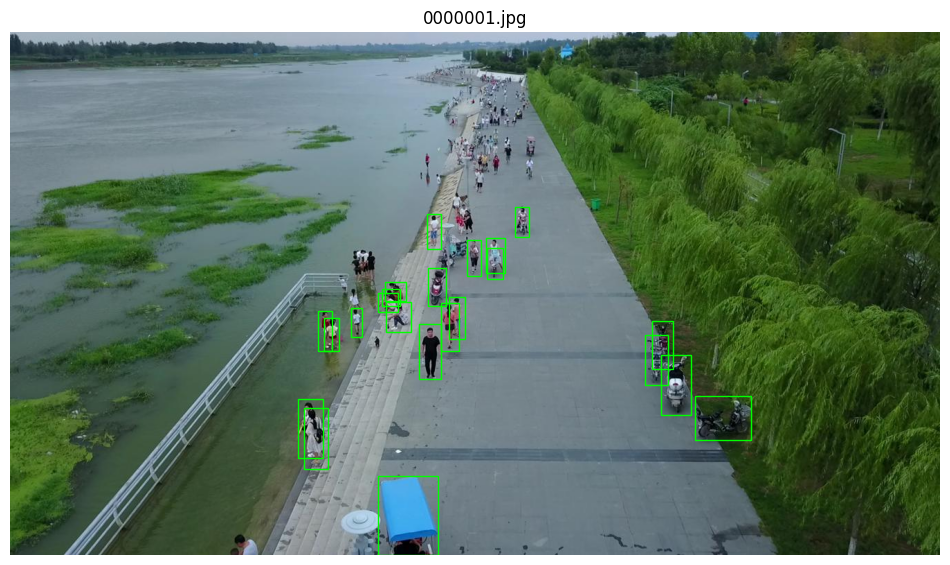

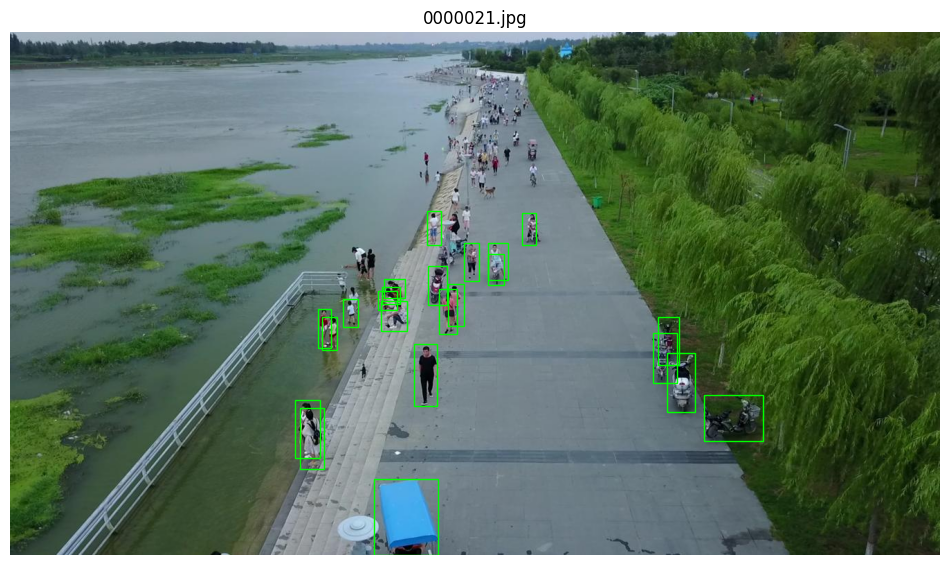

In [5]:
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

examples = sorted((SUBSET / 'images' / 'train').rglob('*.jpg'))[:2]
for img_path in examples:
    relative = img_path.relative_to(SUBSET / 'images' / 'train')
    label_path = (SUBSET / 'labels' / 'train' / relative).with_suffix('.txt')
    img = Image.open(img_path).convert('RGB'); w,h=img.size
    fig,ax=plt.subplots(figsize=(12,7)); ax.imshow(img)
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            v=line.split()
            if len(v)!=5: continue
            cls,cx,cy,bw,bh = map(float,v)
            ax.add_patch(Rectangle(((cx-bw/2)*w,(cy-bh/2)*h),bw*w,bh*h,
                                   fill=False,edgecolor='lime',linewidth=1))
    ax.set_title(img_path.name); ax.axis('off'); plt.show(); plt.close(fig)

## 5. Training protocol and parameter search

We compare three RT-DETR-L configurations initialized with COCO-pretrained weights on the same fixed VisDrone subset.

| Run | Initial learning rate | Input resolution | Hypothesis |
|---|---:|---:|---|
| `baseline` | 0.001 | 640 | Reference performance |
| `lower_lr` | 0.0001 | 640 | More conservative fine-tuning may improve convergence |
| `high_res` | 0.001 | 800 | Preserving more pixels may help small objects |

Run 6 epochs, batch 1, seed 42 for each experiment; record GPU and wall-clock time. **Six epochs for RT-DETR and Faster R-CNN does not imply identical compute budgets.** The previously trained Faster R-CNN on 1,211 images used a different selection method, so the historical comparison is descriptive only. If equal compute cannot be achieved, state that limitation explicitly.

**No extra per-epoch COCO evaluations.** Reuse Ultralytics' normal `results.csv` validation history to display the RT-DETR learning curve. A CNN curve may be overlaid *only* if existing CNN per-epoch validation logs using the same evaluation split are available. Do not invent a curve or rerun each CNN checkpoint simply to fill the plot.


In [6]:
EXPERIMENTS = {
    'baseline': {'imgsz': 640, 'lr0': 0.001},
    'lower_lr': {'imgsz': 640, 'lr0': 0.0001},
    'high_res': {'imgsz': 800, 'lr0': 0.001},
    'baseline_extra6': {'imgsz': 640, 'lr0': 0.000833},
    'finetune_safe': {'imgsz': 640, 'lr0': 0.00001},
    'finetune_extra5': {'imgsz': 640, 'lr0': 0.00001},
}

EPOCHS = 5
BATCH = 1
SEED = 42

RUN_TRAINING = True
RUN_NAMES = ['finetune_extra5']

In [7]:
from ultralytics import RTDETR
from src.models.yolo_baseline import write_dataset_yaml
from huggingface_hub import HfApi
from getpass import getpass
import shutil

TRAIN_YAML = WORK / 'rtdetr_data.yaml'
if (SUBSET / 'images' / 'train').exists():
    write_dataset_yaml(SUBSET, TRAIN_YAML)

HF_REPO = 'lilialania/visdrone-retinanet'
AUTO_BACKUP = True
RESUME_TRAINING = False  # switch on ONLY after restoring the matching last.pt
train_times = {}
from huggingface_hub import hf_hub_download

START_WEIGHTS = hf_hub_download(
    repo_id=HF_REPO,
    filename='query_rtdetr/finetune_safe/weights/best.pt',
    repo_type='model',
    token=os.environ['HF_TOKEN']
)

print("Starting from:", START_WEIGHTS)
def attach_hf_backup(model, run_name, api):
    def on_save(trainer):
        epoch_number = int(trainer.epoch) + 1
        src = Path(trainer.last)
        if not src.is_file():
            raise FileNotFoundError(f'Saved checkpoint missing: {src}')
        # Create immutable local copy before upload
        snapshot = src.parent / f'epoch_{epoch_number:02d}.pt'
        shutil.copy2(src, snapshot)
        remote = f'query_rtdetr/{run_name}/epoch_{epoch_number:02d}.pt'
        api.upload_file(path_or_fileobj=str(snapshot), path_in_repo=remote,
                        repo_id=HF_REPO, repo_type='model')
        if not api.file_exists(repo_id=HF_REPO, filename=remote, repo_type='model'):
            raise RuntimeError(f'HF backup not verified: {remote}')
        history = Path(trainer.save_dir) / 'results.csv'
        if history.is_file():
            api.upload_file(path_or_fileobj=str(history),
                            path_in_repo=f'query_rtdetr/{run_name}/results.csv',
                            repo_id=HF_REPO, repo_type='model')
        print(f'BACKUP VERIFIED: {remote}', flush=True)
    model.add_callback('on_model_save', on_save)

if RUN_TRAINING:
    assert TRAIN_YAML.is_file(), 'Prepare the data first'
    token = os.environ.get("HF_TOKEN")
    assert token, "HF_TOKEN is missing. Check Kaggle Secrets."
    api = HfApi(token=token) if AUTO_BACKUP else None
    if AUTO_BACKUP: print('HF write access:', api.whoami()['name'])
    for run_name in RUN_NAMES:
        cfg = EXPERIMENTS[run_name]
        run_path = RUNS / run_name
        last = run_path / 'weights' / 'last.pt'
        if RESUME_TRAINING:
            assert last.is_file(), f'Restore checkpoint first: {last}'
            model = RTDETR(str(last))
        else:
            if last.is_file():
                raise RuntimeError(f'{last} already exists. Restore/resume explicitly or choose another run name.')
            model = RTDETR(str(START_WEIGHTS))
        if AUTO_BACKUP:
            attach_hf_backup(model, run_name, api)
        t0=time.perf_counter()
        if RESUME_TRAINING:
            model.train(resume=True)
        else:
            model.train(
    data=str(TRAIN_YAML.resolve()),
    epochs=EPOCHS,
    imgsz=cfg['imgsz'],
    batch=BATCH,
    optimizer='AdamW',
    lr0=cfg['lr0'],
    warmup_epochs=0,
    seed=SEED,
    deterministic=True,
    project=str(RUNS),
    name=run_name,
    exist_ok=True,
    workers=2,
    device=0,
    plots=True,
    save=True,
    verbose=True
)
        if AUTO_BACKUP:
            for relative in ('weights/best.pt', 'weights/last.pt', 'results.csv'):
                artifact = run_path / relative
                if artifact.is_file():
                    remote = f'query_rtdetr/{run_name}/{relative}'
                    api.upload_file(path_or_fileobj=str(artifact), path_in_repo=remote,
                                    repo_id=HF_REPO, repo_type='model')
                    print('Final artifact saved:', remote)
        train_times[run_name] = round((time.perf_counter()-t0)/60, 2)
        print(run_name, 'best:', run_path/'weights'/'best.pt',
              'minutes:',train_times[run_name])
else:
    print('Training disabled. Verify prep/labels and backup before enabling.')


query_rtdetr/finetune_safe/weights/best.(…): reconstructing file:   0%|          |  0.00B / 66.2MB            

query_rtdetr/finetune_safe/weights/best.(…): downloading bytes:           |  0.00B            

Starting from: /root/.cache/huggingface/hub/models--lilialania--visdrone-retinanet/snapshots/f7f196ed838b3806e26f6aa0c732781339e8d170/query_rtdetr/finetune_safe/weights/best.pt
HF write access: lilialania
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/query_rtdetr/rtdetr_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        1/5      1.46G     0.6823     0.4858    0.08565        149        640: 100% ━━━━━━━━━━━━ 1238/1238 4.2it/s 4:53
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 11.5it/s 6.4s
                   all        146       5902      0.469      0.409      0.381      0.204


Processing Files (0 / 0): |          |  0.00B /  0.00B            

... (34 outputs left out)

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


Final artifact saved: query_rtdetr/finetune_extra5/weights/last.pt
Final artifact saved: query_rtdetr/finetune_extra5/results.csv
finetune_extra5 best: /kaggle/working/query_rtdetr/runs/finetune_extra5/weights/best.pt minutes: 25.52


### Restore checkpoints after a Kaggle restart

The previous cell backs up every epoch during training. This separate cell retrieves saved `epoch_XX.pt` files if the session was reset. To resume Ultralytics training, place the chosen snapshot at `RUNS/<run>/weights/last.pt` and set `RESUME_TRAINING=True`. Be aware that `resume=True` restores optimizer and training arguments from the saved checkpoint, so use the same experiment name and configuration.


In [8]:
RESTORE_FROM_HF = False
RESTORE_RUN = 'baseline'
RESTORE_EPOCH = 6
if RESTORE_FROM_HF:
    from huggingface_hub import hf_hub_download
    token = os.environ.get('HF_TOKEN') or getpass('Hugging Face token: ')
    remote = f'query_rtdetr/{RESTORE_RUN}/epoch_{RESTORE_EPOCH:02d}.pt'
    downloaded = hf_hub_download(repo_id=HF_REPO, filename=remote,
                                 repo_type='model', token=token)
    destination = RUNS/RESTORE_RUN/'weights'/'last.pt'
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(downloaded, destination)
    print('Restored checkpoint:', destination)
    for rel in ('weights/best.pt', 'results.csv'):
        try:
            path = hf_hub_download(repo_id=HF_REPO,
                 filename=f'query_rtdetr/{RESTORE_RUN}/{rel}',
                 repo_type='model', token=token)
            target = RUNS/RESTORE_RUN/rel
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(path, target)
            print('Restored:', target)
        except Exception as exc:
            print('Optional artifact unavailable:', rel, type(exc).__name__)
else:
    print('Restore disabled; activate only after a restart if needed.')


Restore disabled; activate only after a restart if needed.


## 5B. Query-specific hyperparameters: scope and constraints

RT-DETR performs one-to-one Hungarian matching between predictions and ground-truth objects. Relevant model-specific variables include the number of object queries, assignment cost weights, and auxiliary decoder losses. The VisDrone EDA found up to 180 objects per full frame; the RT-DETR-L configuration typically uses 300 queries, which is relevant to crowded scenes.

**Compute-conscious choice:** In this notebook we do **not** run an additional full validation sweep for query-count ablation and do not modify transformer internals without verifying compatibility. The training experiments change the learning rate and input resolution instead. These are valid hyperparameter comparisons but are not controlled tests of Hungarian-matching-specific settings; document this limitation in the report.


## 6. Evaluate on the original VisDrone validation set

Use the repository's **`src.models.rtdetr evaluate`**, which shares COCO evaluation logic with your other detectors. The default evaluation in that module performs sliced inference. To isolate the **detector's own behavior**, start with `--tile 0` (full-frame only), and use `--step 5` just as in previous Faster R-CNN and RetinaNet validation.

`--full-imgsz` matches each experiment's training input size. Do not report an evaluation metric for a model that has not been trained.

In [9]:
RUN_EVALUATION = False  # Enable only when at least one best.pt is available
EVAL_LOGS = WORK/'eval_logs'
EVAL_LOGS.mkdir(parents=True,exist_ok=True)

if RUN_EVALUATION:
    for run_name in RUN_NAMES:
        best=RUNS/run_name/'weights'/'best.pt'
        if not best.is_file():
            print('Skipping missing checkpoint:',run_name)
            continue
        cmd=[sys.executable,'-u','-m','src.models.rtdetr','evaluate',
             '--weights',str(best), '--split-root',str(DATA_ROOT/'val'),
             '--step','5','--tile','0',
             '--full-imgsz',str(EXPERIMENTS[run_name]['imgsz']),'--conf','0.01']
        with (EVAL_LOGS/f'{run_name}.txt').open('w') as logfile:
            process=subprocess.run(cmd,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True)
            logfile.write(process.stdout)
        print(f'\n=== {run_name}: return code {process.returncode} ===')
        print(process.stdout[-3000:])
        if process.returncode:
            raise RuntimeError(f'Evaluation failed for {run_name}; see log')
else:
    print('Evaluation skipped until trained weights exist.')

Evaluation skipped until trained weights exist.


### Validation results table

This cell parses **actual** COCO evaluation logs and leaves missing runs as `NaN`. `AP_small` / AP50 / FPS should be reported only after a successful run. Keep the raw logs in the notebook or in experiment artifacts.

In [10]:
import pandas as pd, re

def parse_eval_log(path):
    text=path.read_text() if path.exists() else ''
    def get(pattern):
        m=re.search(pattern,text)
        return float(m.group(1)) if m else float('nan')
    ms=get(r'Inference:\s*([0-9.]+)\s*ms/image')
    return {
        'mAP@50:95':get(r'IoU=0\.50:0\.95\s*\|\s*area=\s*all\s*\|\s*maxDets=100\s*\]\s*=\s*([0-9.]+)'),
        'AP50':get(r'IoU=0\.50\s*\|\s*area=\s*all\s*\|\s*maxDets=500\s*\]\s*=\s*([0-9.]+)'),
        'AP_small':get(r'IoU=0\.50:0\.95\s*\|\s*area=\s*small\s*\|\s*maxDets=500\s*\]\s*=\s*([0-9.]+)'),
        'ms/image':ms,
        'FPS':1000/ms if ms==ms and ms>0 else float('nan')
    }

rt_results=pd.DataFrame({name:parse_eval_log(EVAL_LOGS/f'{name}.txt') for name in RUN_NAMES}).T
rt_results.index.name='RT-DETR experiment'
display(rt_results.round(4))
rt_results.to_csv(WORK/'rtdetr_validation_summary.csv')

,mAP@50:95,AP50,AP_small,ms/image,FPS
RT-DETR experiment,,,,,
finetune_extra5,NaN,NaN,NaN,NaN,NaN


### Compute budget and comparison note

Use the time printed by the training cell (`train_times`), GPU type from Setup, input resolution, number of images, and batch size in the report. Do not present the 6-epoch Faster R-CNN result as a fully matched-budget CNN comparison without verifying the data and GPU time. If no matching CNN learning-curve log exists, show the available final CNN metric only in the summary table and explicitly acknowledge the missing curve requirement.


## 7. Training dynamics: validation mAP during training (no extra inference)

Each RT-DETR training run normally writes `results.csv`, including mAP recorded during the training process. We plot these **existing** values, without running inference separately for every epoch. Section 6 still evaluates only the final selected checkpoint on the original VisDrone validation set at step 5.

The grading rubric asks for RT-DETR versus a CNN detector under a comparable compute budget. **An earlier Faster R-CNN final validation score (0.1675) is not a learning curve.** Add a CNN curve **only when existing per-epoch validation data are available**, measured on the same validation frames under a documented budget. Otherwise, explicitly record this criterion as outstanding; no expensive retrospective checkpoint-by-checkpoint evaluation is scheduled.


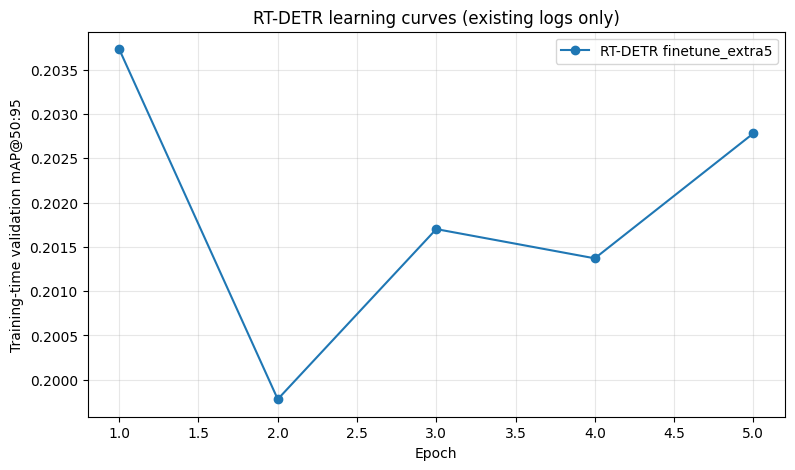

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

fig,ax=plt.subplots(figsize=(9,5))
curves=0
for run_name in RUN_NAMES:
    path=RUNS/run_name/'results.csv'
    if not path.exists():continue
    history=pd.read_csv(path)
    history.columns=history.columns.str.strip()
    ap_cols=[col for col in history.columns if 'mAP50-95' in col and '(B)' in col]
    if not ap_cols:print('No mAP column:',path);continue
    ax.plot(history['epoch'] if 'epoch' in history.columns else range(1,len(history)+1),
            history[ap_cols[0]], marker='o', label='RT-DETR '+run_name)
    curves+=1
CNN_CURVE_CSV = None  # Existing matched-budget CNN per-epoch CSV, if available; do NOT recompute checkpoints
if CNN_CURVE_CSV and Path(CNN_CURVE_CSV).exists():
    cnn=pd.read_csv(CNN_CURVE_CSV)
    assert {'epoch','map5095'}.issubset(cnn.columns), 'CNN CSV needs columns epoch,map5095'
    ax.plot(cnn['epoch'],cnn['map5095'],marker='s',label='CNN baseline (matched budget)')
    curves+=1
ax.set(xlabel='Epoch',ylabel='Training-time validation mAP@50:95',title='RT-DETR learning curves (existing logs only)')
ax.grid(alpha=.3)
if curves:ax.legend()
else:ax.text(.5,.5,'Run training to generate history',ha='center',va='center',transform=ax.transAxes)
plt.show();plt.close(fig)

### Interpretation template (fill after running)

- **Baseline RT-DETR:** final mAP@50:95 = **TODO (after training)**, AP_small = **TODO (after training)**, training time = **TODO (after training)**.
- **Learning-rate adjustment:** compared with baseline, mAP changed by **TODO (after training)**; early convergence became **TODO (after training)**.
- **Higher input resolution:** AP_small changed by **TODO (after training)** at the expense of **TODO (after training)** speed/memory.
- **Comparison to Faster R-CNN:** with a genuinely matched data/budget/validation setup, the observed difference is **TODO (after training)**. Until then, Faster R-CNN's earlier `0.1675` is only a reference.
- **Convergence:** if mAP is still increasing in epoch 6, note explicitly that RT-DETR may not have converged within the training budget.

**Do not replace TODO with guessed outcomes.**

## 8. Failure cases: ground truth versus RT-DETR predictions

The model must be assessed on both **small objects and dense frames**. Select dense frames from the original validation COCO annotations (rather than simply taking the first three frames), visualize GT in **green** and predictions in **red**, and report at least three examples: a missed small object, a localization problem, and overlapping / confused classes.

These pictures are **qualitative evidence**, not a substitute for the official COCO AP_small. Ground-truth annotations may include ignored regions; do not count detections within ignored regions as errors without applying the dataset's ignore policy.


In [12]:
SHOW_FAILURE_EXAMPLES = False
if SHOW_FAILURE_EXAMPLES:
    import json
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle
    from PIL import Image
    from ultralytics import RTDETR
    coco = json.loads((DATA_ROOT/'val'/'annotations_coco.json').read_text())
    images_by_id = {im['id']: im for im in coco['images']}
    annotations_by_id = {}
    for ann in coco['annotations']:
        annotations_by_id.setdefault(ann['image_id'], []).append(ann)
    ranked = sorted(images_by_id.values(),
                    key=lambda im: len(annotations_by_id.get(im['id'], [])), reverse=True)
    best = RUNS/'baseline'/'weights'/'best.pt'
    assert best.is_file(), 'Train or restore the baseline first'
    model = RTDETR(str(best))
    shown = 0
    for info in ranked:
        # The metadata file_name layout varies; use the known filename as a fallback
        candidate = DATA_ROOT/'val'/info['file_name']
        if not candidate.is_file():
            matches = list((DATA_ROOT/'val'/'images').rglob(Path(info['file_name']).name))
            if not matches:
                continue
            candidate = matches[0]
        image = Image.open(candidate).convert('RGB')
        prediction = model.predict(str(candidate), imgsz=640, conf=.05,
                                   max_det=500, verbose=False)[0]
        fig, ax = plt.subplots(figsize=(12, 7))
        ax.imshow(image)
        for ann in annotations_by_id.get(info['id'], []):
            x,y,w,h = ann['bbox']
            if w>0 and h>0:
                ax.add_patch(Rectangle((x,y),w,h,fill=False,edgecolor='lime',linewidth=1))
        for b in prediction.boxes.xyxy.cpu().numpy():
            x1,y1,x2,y2=map(float,b)
            if x2>x1 and y2>y1:
                ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,
                                       fill=False,edgecolor='red',linewidth=1))
        ax.set_title(f"{candidate.name}: {len(annotations_by_id.get(info['id'], []))} GT (green), {len(prediction.boxes)} predictions (red)")
        ax.axis('off'); plt.show(); plt.close(fig)
        shown += 1
        if shown == 3:break
    print('Frames visualized:',shown)
    print('Write per-frame analysis below: missed small objects, overlap, incorrect classes, ignore regions.')
else:
    print('Failure analysis disabled until a trained checkpoint exists.')


Failure analysis disabled until a trained checkpoint exists.


### Failure-case interpretation (fill after inspecting figures)

| Frame ID | Density / small-object issue | Observed GT vs predicted boxes | Plausible cause | Follow-up experiment |
|---|---|---|---|---|
| TODO | Missed small object | TODO | Insufficient visual resolution / weak features (hypothesis) | Increase resolution |
| TODO | Dense scene / overlapping vehicles | TODO | Query competition or occlusion (hypothesis) | Query-count ablation |
| TODO | Localization or class confusion | TODO | Similar appearance / overlap (hypothesis) | Review class-specific AP |

**Do not call these examples confirmed failures before visual inspection.**


## 9. Final model comparison and conclusions

| Detector | Type | mAP@50:95 (val) | AP50 | AP_small | FPS | Notes |
|---|---|---:|---:|---:|---:|---|
| RetinaNet baseline | One-stage anchor-based | 0.1468 | 0.2820 | 0.0423 | 7.9 | Earlier experiment; different training subset |
| RetinaNet small anchors | One-stage anchor-based | 0.1459 | 0.3151 | 0.0608 | 8.0 | Earlier experiment; different training subset |
| Faster R-CNN | Two-stage anchor-based | 0.1675 | 0.3611 | 0.0873 | 4.1 | Earlier experiment |
| RT-DETR baseline | Query-based | **TODO** | **TODO** | **TODO** | **TODO** | Evaluate first |
| RT-DETR tuned | Query-based | **TODO** | **TODO** | **TODO** | **TODO** | Select best setting after validation |

**Report after running:** best tuning configuration; whether convergence was reached; AP_small and crowded-scene limitations; trade-off between mAP and FPS; and whether results are fully comparable despite preprocessing differences.

### Rubric checklist

- [ ] Query-based pretrained detector trained under documented budget
- [ ] Learning rate and input-resolution tuning completed; query-specific training hyperparameters not changed
- [ ] Validation mAP, AP50, AP_small, inference time recorded
- [ ] Hungarian matching and NMS explained
- [ ] RT-DETR mAP curve plotted from existing training logs
- [ ] CNN learning curve added *if existing comparable logs are available*; otherwise report rubric gap (no extra evaluation)
- [ ] Three illustrated failure cases (small and dense scenes)
- [ ] Checkpoints, configuration, and results backed up

**Scope:** this notebook documents the Query-based part of the coursework. Final ensemble/SAHI/WBF pipeline belongs in a separate notebook.